**Task 1** Average inspection score by borough

In [41]:
import pandas as pd

id_dtypes = {
    "ZIPCODE": "string",
    "Community Board": "string",
    "Council District": "string",
    "Census Tract": "string",
    "BIN": "string",
    "BBL": "string",
}

df_prepared = pd.read_csv(
    "/Users/joshikaindrakumar/Documents/GitHub/nyc-restaurant-inspections-1/handoff/restaurants_prepared.csv",
    dtype=id_dtypes,
    parse_dates=["INSPECTION DATE", "GRADE DATE", "RECORD DATE"],
    low_memory=False,
)

inspection_key = ["CAMIS", "INSPECTION DATE", "INSPECTION TYPE"]
inspection_level_for_eda = (
    df_prepared.loc[~df_prepared["AWAITING_INSPECTION"]]
    .sort_values("SOURCE_ROW_ID", kind="stable")
    .drop_duplicates(subset=inspection_key, keep="first")
)

scored_inspections = inspection_level_for_eda.loc[
    inspection_level_for_eda["SCORE"].notna()
    & inspection_level_for_eda["BORO"].notna()
    & ~inspection_level_for_eda["BORO_UNKNOWN"]
]

borough_score_summary = (
    scored_inspections.groupby("BORO", as_index=False)
    .agg(
        inspection_count=("SCORE", "count"),
        average_score=("SCORE", "mean"),
    )
    .sort_values("BORO")
    .reset_index(drop=True)
)

borough_score_summary

,BORO,inspection_count,average_score
0,Bronx,7706,17.574358
1,Brooklyn,21412,17.972305
2,Manhattan,31393,17.205906
3,Queens,19429,19.192187
4,Staten Island,2922,16.870979


**Task 2** Score distribution (histogram/boxplot)


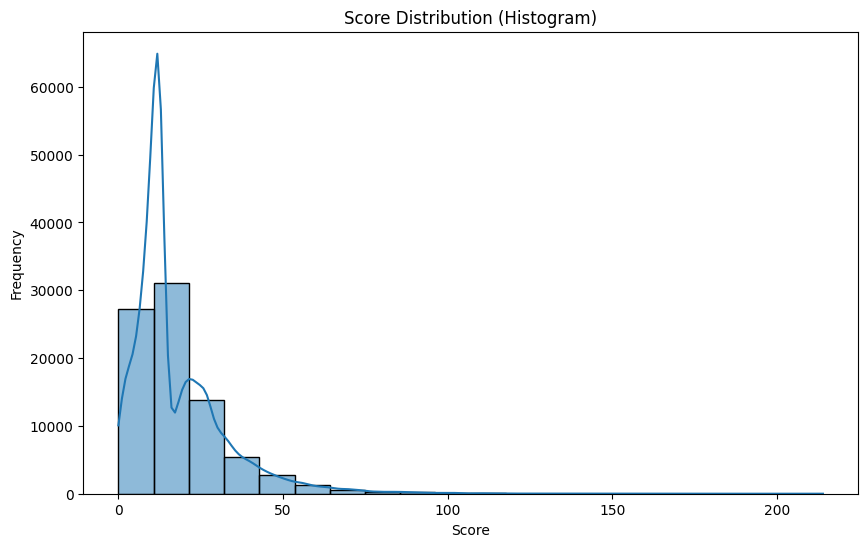

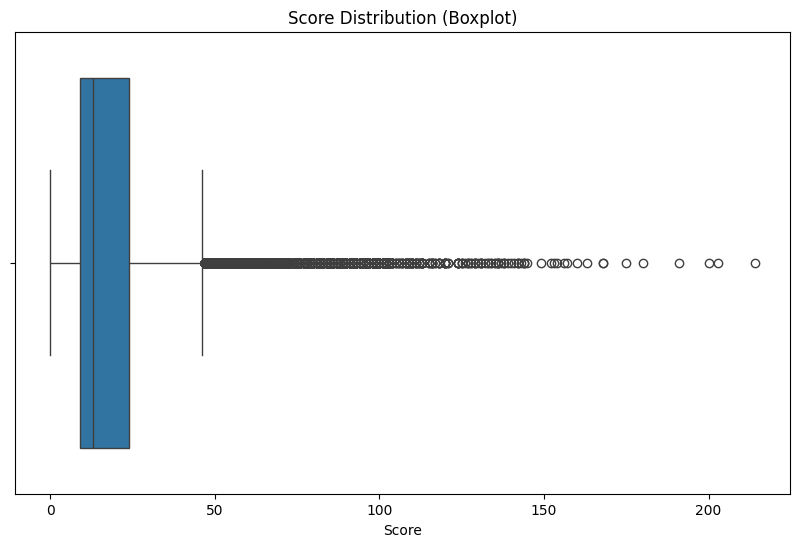

In [42]:
import matplotlib.pyplot as plt
import seaborn as sns

# Histogram
plt.figure(figsize=(10, 6))
sns.histplot(scored_inspections["SCORE"], bins=20, kde=True)
plt.title("Score Distribution (Histogram)")
plt.xlabel("Score")
plt.ylabel("Frequency")
plt.show()

# Boxplot
plt.figure(figsize=(10, 6))
sns.boxplot(x="SCORE", data=scored_inspections)
plt.title("Score Distribution (Boxplot)")
plt.xlabel("Score")
plt.show()

**Task 3** Grade distribution (A/B/C)

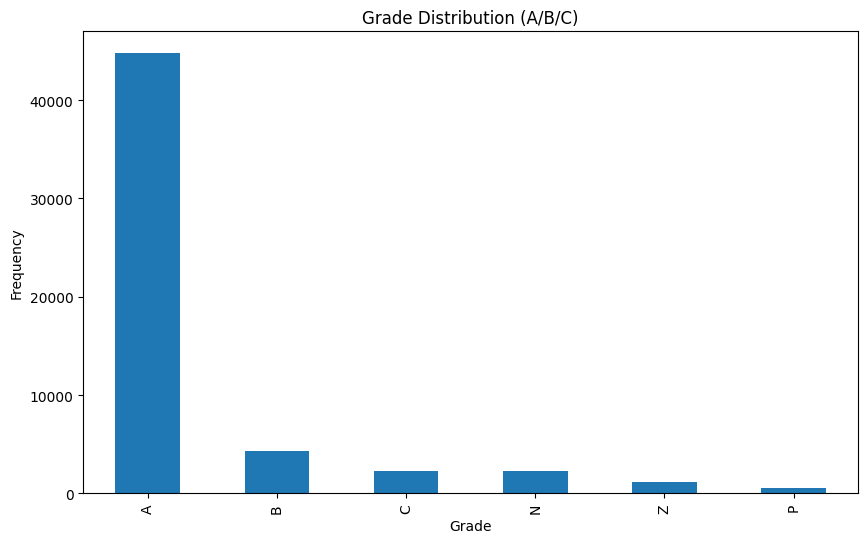

In [43]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
scored_inspections["GRADE"].value_counts().plot(kind="bar")
plt.title("Grade Distribution (A/B/C)")
plt.xlabel("Grade")
plt.ylabel("Frequency")
plt.show()

**Task 4** Initial vs. reinspection comparisons

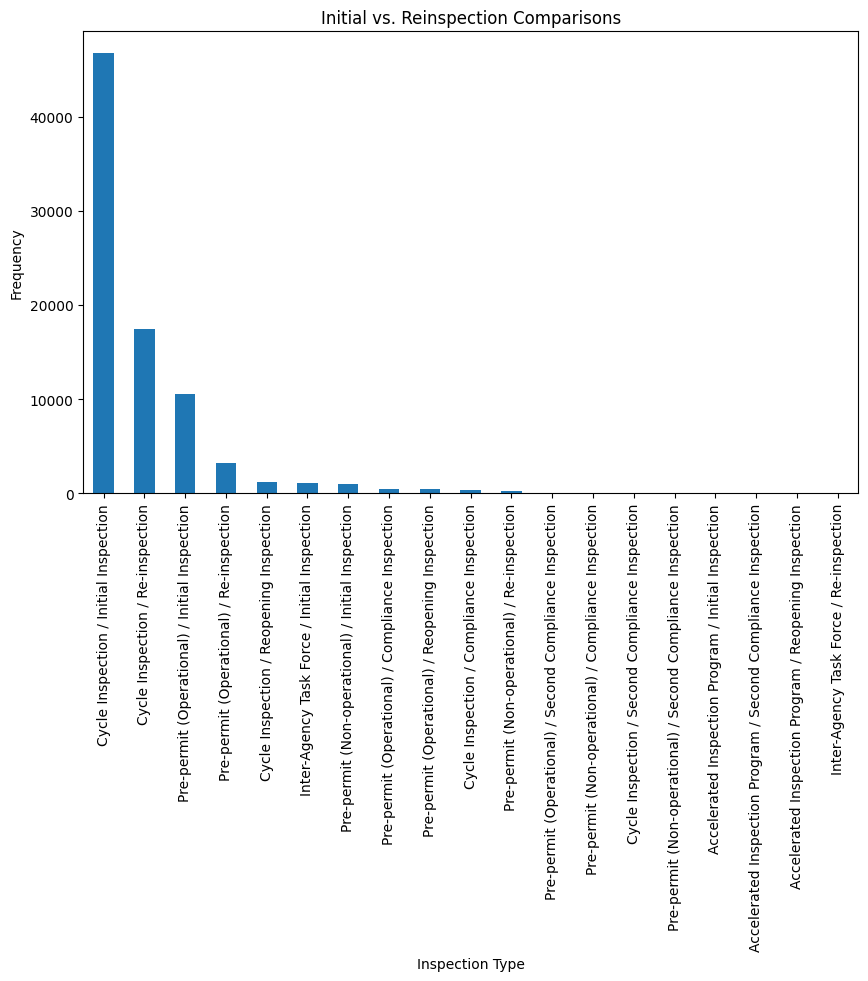

In [44]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
scored_inspections["INSPECTION TYPE"].value_counts().plot(kind="bar")
plt.title("Initial vs. Reinspection Comparisons")
plt.xlabel("Inspection Type")
plt.ylabel("Frequency")
plt.show()

**Task 5** Inspection trends over time

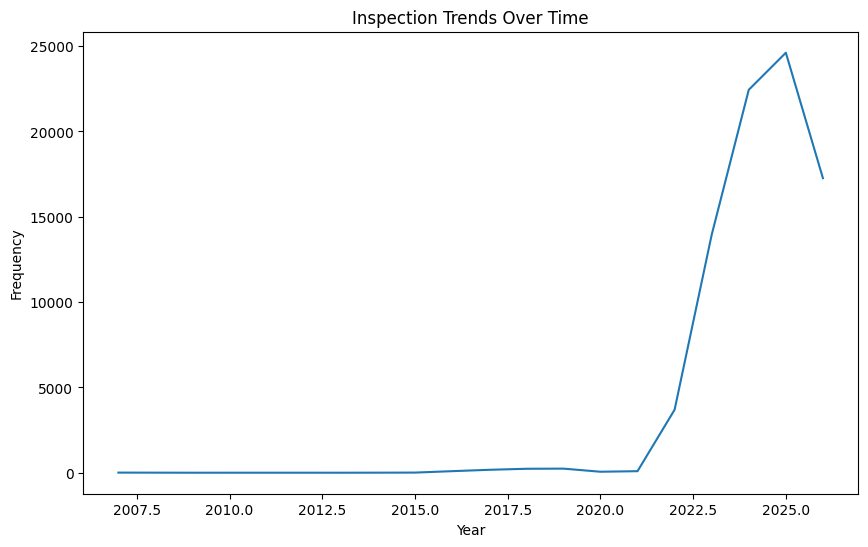

In [45]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
scored_inspections["INSPECTION DATE"].dt.year.value_counts().sort_index().plot(kind="line")
plt.title("Inspection Trends Over Time")
plt.xlabel("Year")
plt.ylabel("Frequency")
plt.show()

In [46]:
print(scored_inspections.columns)

Index(['SOURCE_ROW_ID', 'CAMIS', 'DBA', 'BORO', 'BUILDING', 'STREET',
       'ZIPCODE', 'PHONE', 'CUISINE DESCRIPTION', 'INSPECTION DATE', 'ACTION',
       'VIOLATION CODE', 'VIOLATION DESCRIPTION', 'CRITICAL FLAG', 'SCORE',
       'GRADE', 'GRADE DATE', 'RECORD DATE', 'INSPECTION TYPE', 'Latitude',
       'Longitude', 'Community Board', 'Council District', 'Census Tract',
       'BIN', 'BBL', 'NTA', 'Location', 'AWAITING_INSPECTION', 'BORO_UNKNOWN',
       'ZERO_COORDINATES', 'BBL_INCOMPLETE'],
      dtype='str')


**Task 6** Closure/action frequencies

/var/folders/b8/_jqmrgnn0fngz565b27_l8800000gn/T/ipykernel_10607/96092508.py:14: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


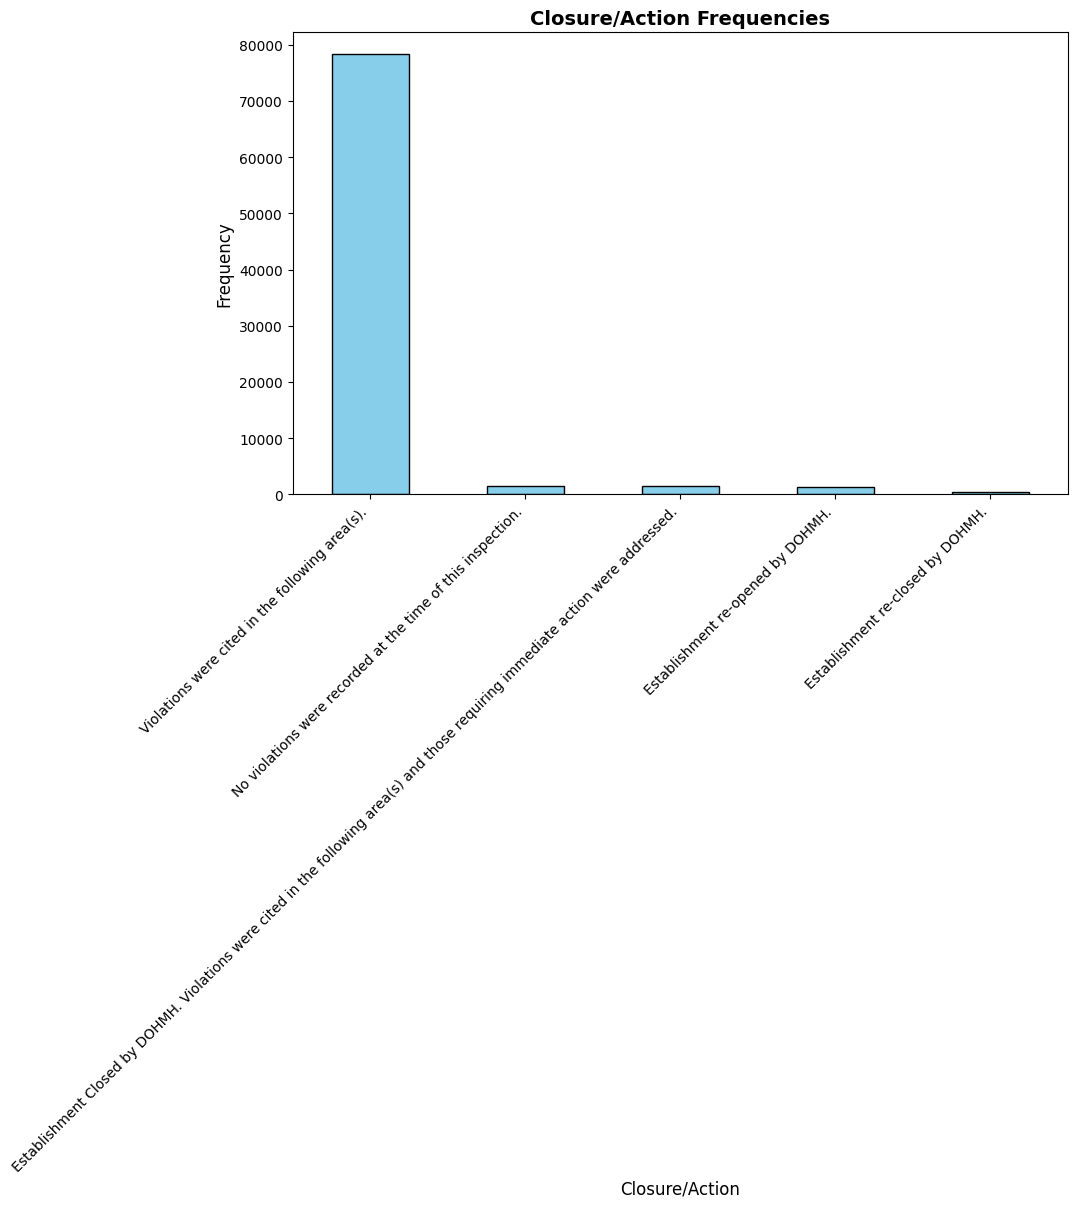

In [47]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
scored_inspections["ACTION"].value_counts().plot(kind="bar", color="skyblue", edgecolor="black")

plt.title("Closure/Action Frequencies", fontsize=14, fontweight="bold")
plt.xlabel("Closure/Action", fontsize=12)
plt.ylabel("Frequency", fontsize=12)

# Rotate x-axis labels for better readability and align them
plt.xticks(rotation=45, ha="right")

# Automatically adjust layout so labels aren't cut off
plt.tight_layout()
plt.show()

**Task 7** Historical average score per restaurant

In [48]:
restaurant_score_summary = (
    inspection_level_for_eda.loc[inspection_level_for_eda["SCORE"].notna()]
    .groupby("CAMIS", as_index=False)
    .agg(
        DBA=("DBA", "first"),
        inspections_with_score=("SCORE", "count"),
        average_score=("SCORE", "mean"),
    )
    .sort_values("average_score", ascending=False)
    .reset_index(drop=True)
)

restaurant_score_summary

,CAMIS,DBA,inspections_with_score,average_score
0,50182863,TAPAS ON LEX,1,214.0
1,50177707,JOYBITE TANGHULU,1,203.0
2,50178495,JAY & SON LATIN FLAVOR,1,200.0
3,50132754,LE PAIN QUOTIDIEN,1,168.0
4,50182313,GLACE BY NOGLU,1,152.0
...,...,...,...,...
27642,50045112,GARDEN PUB,2,0.0
27643,41416592,SOUTH SHORE LITTLE LEAGUE,2,0.0
27644,50181136,MALAVITA,1,0.0
27645,50044592,"CHICKEN, FRIES CONCESSION",2,0.0


**Task 8** A-grade ratio over time

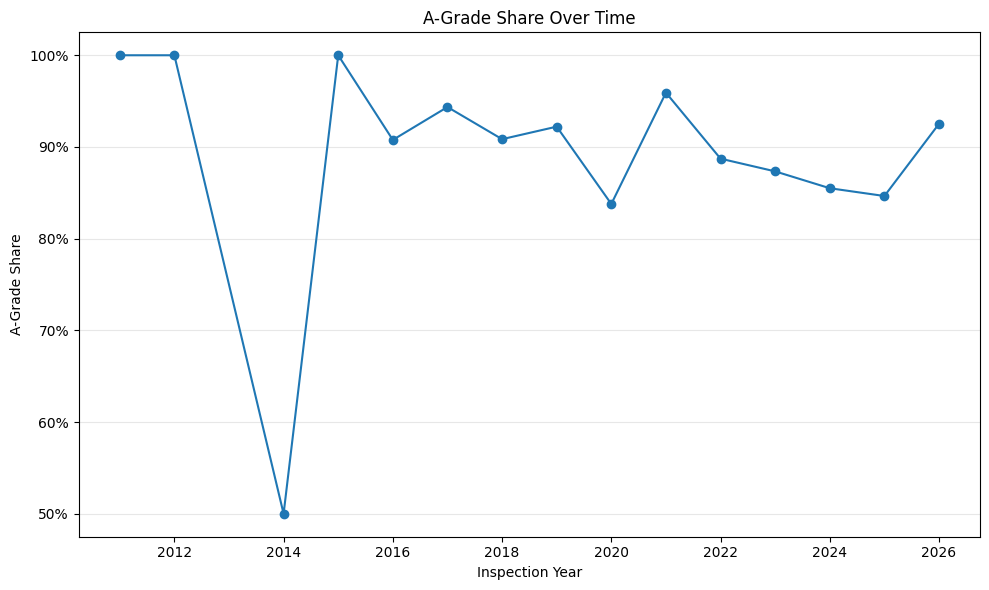

,year,graded_inspections,a_grade_inspections,a_grade_ratio
0,2011,1,1,1.000000
1,2012,1,1,1.000000
2,2014,2,1,0.500000
3,2015,5,5,1.000000
4,2016,65,59,0.907692
5,2017,124,117,0.943548
6,2018,153,139,0.908497
7,2019,167,154,0.922156
8,2020,37,31,0.837838
9,2021,49,47,0.959184


In [49]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

grade_trend = (
    inspection_level_for_eda.loc[
        inspection_level_for_eda["GRADE"].isin(["A", "B", "C"]),
        ["INSPECTION DATE", "GRADE"],
    ]
    .assign(year=lambda data: data["INSPECTION DATE"].dt.year)
    .groupby("year", as_index=False)
    .agg(
        graded_inspections=("GRADE", "size"),
        a_grade_inspections=("GRADE", lambda grades: grades.eq("A").sum()),
    )
)
grade_trend["a_grade_ratio"] = (
    grade_trend["a_grade_inspections"] / grade_trend["graded_inspections"]
)

plt.figure(figsize=(10, 6))
plt.plot(grade_trend["year"], grade_trend["a_grade_ratio"], marker="o")
plt.title("A-Grade Share Over Time")
plt.xlabel("Inspection Year")
plt.ylabel("A-Grade Share")
plt.gca().yaxis.set_major_formatter(PercentFormatter(1))
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

grade_trend

**Task 9** Repeat violation rates

In [50]:
repeat_violation_rates = (
    inspection_level_for_eda.loc[inspection_level_for_eda["VIOLATION DESCRIPTION"].notna()]
    .groupby("CAMIS", as_index=False)
    .agg(
        total_violations=("VIOLATION DESCRIPTION", "count"),
        repeat_violations=("VIOLATION DESCRIPTION", lambda x: x.duplicated().sum()),
    )
    .assign(
        repeat_violation_rate=lambda df: df["repeat_violations"] / df["total_violations"]
    )
    .sort_values("repeat_violation_rate", ascending=False)
    .reset_index(drop=True)
)
repeat_violation_rates

,CAMIS,total_violations,repeat_violations,repeat_violation_rate
0,50106901,4,3,0.75
1,50080887,4,3,0.75
2,50151520,4,3,0.75
3,50139134,4,3,0.75
4,50018146,4,3,0.75
...,...,...,...,...
27554,50084913,3,0,0.00
27555,50084903,2,0,0.00
27556,50084831,2,0,0.00
27557,50084796,7,0,0.00


**Task 10** Predictive modeling using restaurant history

In [51]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

model_data = inspection_level_for_eda.sort_values(
    ["CAMIS", "INSPECTION DATE", "SOURCE_ROW_ID"], kind="stable"
).copy()
restaurant_groups = model_data.groupby("CAMIS", sort=False)
model_data["prior_inspection_count"] = restaurant_groups.cumcount()
model_data["prior_score"] = restaurant_groups["SCORE"].transform(
    lambda scores: scores.ffill().shift(1)
)
model_data["prior_mean_score"] = restaurant_groups["SCORE"].transform(
    lambda scores: scores.expanding().mean().shift(1)
)

categorical_features = ["BORO", "CUISINE DESCRIPTION", "INSPECTION TYPE"]
numeric_features = [
    "prior_inspection_count",
    "prior_score",
    "prior_mean_score",
]
feature_columns = categorical_features + numeric_features

scored_model_data = model_data.loc[
    model_data["SCORE"].notna() & model_data["INSPECTION DATE"].notna()
].copy()
test_start_date = scored_model_data["INSPECTION DATE"].quantile(0.8)
train_data = scored_model_data.loc[
    scored_model_data["INSPECTION DATE"] < test_start_date
]
test_data = scored_model_data.loc[
    scored_model_data["INSPECTION DATE"] >= test_start_date
]

numeric_pipeline = Pipeline(
    steps=[("imputer", SimpleImputer(strategy="median", add_indicator=True))]
)
categorical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]
)
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features),
    ]
)
score_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "regressor",
            RandomForestRegressor(
                n_estimators=100,
                max_depth=14,
                min_samples_leaf=10,
                n_jobs=-1,
                random_state=42,
            ),
        ),
    ]
)

score_model.fit(train_data[feature_columns], train_data["SCORE"])
predicted_scores = score_model.predict(test_data[feature_columns])
baseline_scores = [train_data["SCORE"].median()] * len(test_data)

model_performance = pd.DataFrame(
    [
        {
            "test_start_date": test_start_date.date(),
            "training_inspections": len(train_data),
            "test_inspections": len(test_data),
            "model_mae": mean_absolute_error(test_data["SCORE"], predicted_scores),
            "baseline_mae": mean_absolute_error(test_data["SCORE"], baseline_scores),
            "model_rmse": mean_squared_error(test_data["SCORE"], predicted_scores) ** 0.5,
            "model_r2": r2_score(test_data["SCORE"], predicted_scores),
        }
    ]
)

model_performance

,test_start_date,training_inspections,test_inspections,model_mae,baseline_mae,model_rmse,model_r2
0,2026-01-13,66341,16615,10.311393,10.811255,15.401278,0.115075
